# Joint analysis of paired RNA + ATAC

10x Multiome measures gene expression and chromatin accessibility in the same
cell. This tutorial reads cellranger-arc output, builds per-modality
embeddings, and compares four ways of combining them:

| method | function | idea |
|---|---|---|
| combined dims | `epi.tl.combined_dims` | concatenate the embeddings, each scaled to the same total variance (ArchR `addCombinedDims`) |
| WNN | `epi.tl.wnn` | per-cell modality weights, then a weighted nearest-neighbour graph (Hao *et al.*, Cell 2021) |
| MultiVI | `epi.tl.multivi` | a deep generative joint latent space (Ashuach *et al.*, Nat Methods 2023; scvi-tools) |
| CCA | `epi.tl.integrate` | canonical correlation between RNA and ATAC gene activity |

It also computes a t-SNE with `epi.tl.tsne` (openTSNE / FIt-SNE). The data are
the public 10x PBMC 10k Multiome sample (9,631 annotated cells).
`epi.tl.multivi` and `epi.tl.tsne` need `pip install 'epione[multimodal]'`.

In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import epione as epi

sc.settings.verbosity = 0
DATA = os.environ.get("EPIONE_PBMC10K_DIR")        # None -> pooch cache
DATA_10X = os.environ.get("EPIONE_PBMC10K_10X_DIR")

## Read cellranger-arc output

`epi.io.read_10x_multiome` takes the cellranger-arc `outs/` folder, the
`filtered_feature_bc_matrix.h5` file or the matrix folder, splits Gene
Expression from Peaks, parses peak coordinates and adds
`per_barcode_metrics.csv` to `obs`. When `atac_fragments.tsv.gz` sits next to
the matrix, its path goes to `atac.uns["files"]["fragments"]`, where Epione's
fragment-based tools look for it. Here we fetch only the matrix and the
metrics from 10x Genomics (the 2 GB fragment file is skipped). Pass
`as_mudata=True` for a MuData, or `backed="sample.h5mu"` to work out of core
through mudataoom.

In [2]:
rna10x, atac10x = epi.io.read_10x_multiome(epi.datasets.pbmc10k_multiome_10x(DATA_10X))
print(rna10x)
print(atac10x.var[["chrom", "chromStart", "chromEnd"]].head(3))
rna10x.obs["rna_counts"] = np.asarray(rna10x.X.sum(axis=1)).ravel()
rna10x.obs[["rna_counts", "atac_fragments", "atac_TSS_fragments", "atac_peak_region_cutsites"]].describe().loc[["mean", "50%"]]

AnnData object with n_obs × n_vars = 11898 × 36601
    obs: 'gex_barcode', 'atac_barcode', 'is_cell', 'excluded_reason', 'gex_raw_reads', 'gex_mapped_reads', 'gex_conf_intergenic_reads', 'gex_conf_exonic_reads', 'gex_conf_intronic_reads', 'gex_conf_exonic_unique_reads', 'gex_conf_exonic_antisense_reads', 'gex_conf_exonic_dup_reads', 'gex_exonic_umis', 'gex_conf_intronic_unique_reads', 'gex_conf_intronic_antisense_reads', 'gex_conf_intronic_dup_reads', 'gex_intronic_umis', 'gex_conf_txomic_unique_reads', 'gex_umis_count', 'gex_genes_count', 'atac_raw_reads', 'atac_unmapped_reads', 'atac_lowmapq', 'atac_dup_reads', 'atac_chimeric_reads', 'atac_mitochondrial_reads', 'atac_fragments', 'atac_TSS_fragments', 'atac_peak_region_fragments', 'atac_peak_region_cutsites'
    var: 'gene_ids', 'feature_types', 'genome', 'interval'
                   chrom  chromStart  chromEnd
chr1:9790-10675     chr1        9790     10675
chr1:180599-181702  chr1      180599    181702
chr1:191168-192093  chr1      

,rna_counts,atac_fragments,atac_TSS_fragments,atac_peak_region_cutsites
mean,4407.349609,18042.062363,9297.884434,23039.334174
50%,3777.500000,17305.500000,9388.000000,23072.000000


For the analysis we use the scGLUE release of the same sample, which adds
Seurat-WNN cell-type labels (`obs["cell_type"]`). Its RNA counts are
identical to the cellranger-arc matrix on the shared cells; its ATAC peaks
were called separately (107,194 vs 143,887 peaks).

In [3]:
rna, atac = epi.datasets.pbmc10k_multiome(DATA)
shared = rna.obs_names.intersection(rna10x.obs_names)
print(rna.shape, atac.shape, f"{len(shared)} of {rna.n_obs} cells are in the cellranger-arc matrix")

(9631, 29095) (9631, 107194) 9627 of 9631 cells are in the cellranger-arc matrix


## Per-modality embeddings

RNA: 2,000 highly variable genes, log-normalised, scaled, 50 PCs.
ATAC: TF-IDF and SVD (`epi.tl.lsi`), 50 components; the first component
tracks sequencing depth and is left out downstream.

In [4]:
r = rna.copy()
sc.pp.highly_variable_genes(r, n_top_genes=2000, flavor="seurat_v3")
sc.pp.normalize_total(r, target_sum=1e4); sc.pp.log1p(r)
r = r[:, r.var.highly_variable].copy()
sc.pp.scale(r, max_value=10)
sc.tl.pca(r, n_comps=50, random_state=0)

a = atac.copy()
epi.tl.lsi(a, n_components=50, remove_first_component=False, random_state=0)

joint = sc.AnnData(np.zeros((rna.n_obs, 1)), obs=rna.obs[["cell_type"]].copy())
joint.obsm["X_pca"] = r.obsm["X_pca"]
joint.obsm["X_lsi"] = a.obsm["X_lsi"]
joint.obsm["X_lsi_2_50"] = a.obsm["X_lsi"][:, 1:]
joint

  └─ Starting optimized LSI analysis...
  └─ Computing TF-IDF normalization...


  └─ Applying L1 normalization and log transformation...


  └─ Performing randomized SVD...


  └─ Standardizing embeddings...
  └─ LSI analysis completed!


AnnData object with n_obs × n_vars = 9631 × 1
    obs: 'cell_type'
    obsm: 'X_pca', 'X_lsi', 'X_lsi_2_50'

## t-SNE of the ATAC embedding

`epi.tl.tsne` runs openTSNE (FIt-SNE) on any representation, here LSI
components 2–50 with cosine distance, and writes `obsm["X_tsne"]` for
`epi.pl.tsne`.

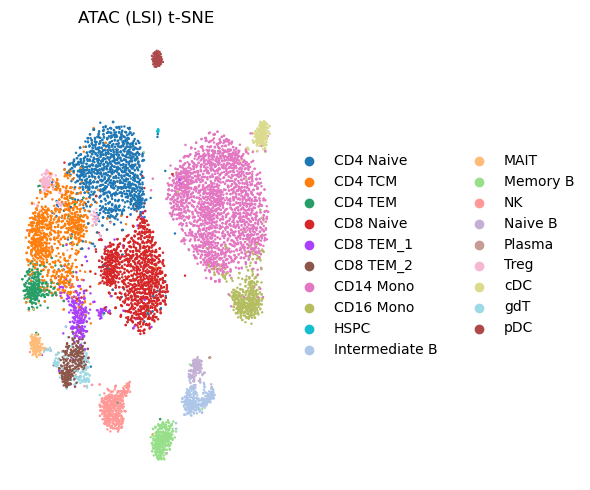

In [5]:
epi.tl.tsne(joint, use_rep="X_lsi", dims=range(2, 51))
fig, ax = plt.subplots(figsize=(6, 5))
sc.pl.embedding(joint, "X_tsne", color="cell_type", ax=ax, show=False, frameon=False, title="ATAC (LSI) t-SNE")
plt.tight_layout()

## Combined dims

`epi.tl.combined_dims` follows ArchR `addCombinedDims` exactly: each
embedding is divided by the square root of its total variance, so RNA (50
dims) and ATAC (49 dims) contribute equally. On ArchR's hematopoiesis project
it reproduces `addCombinedDims` to 1e-14.

In [6]:
epi.tl.combined_dims(joint, ["X_pca", "X_lsi_2_50"], key_added="X_combined")
sc.pp.neighbors(joint, use_rep="X_combined", n_neighbors=20, key_added="combined", random_state=0)

## Weighted nearest neighbours

For every cell, WNN compares how well its RNA profile is predicted by its RNA
neighbours versus by its ATAC neighbours, and the same for ATAC. The
resulting per-cell weights say which modality describes that cell better;
the graph then links each cell to the neighbours with the highest weighted
affinity. The graph is stored in scanpy format, so UMAP and Leiden take
`neighbors_key="wnn"`.

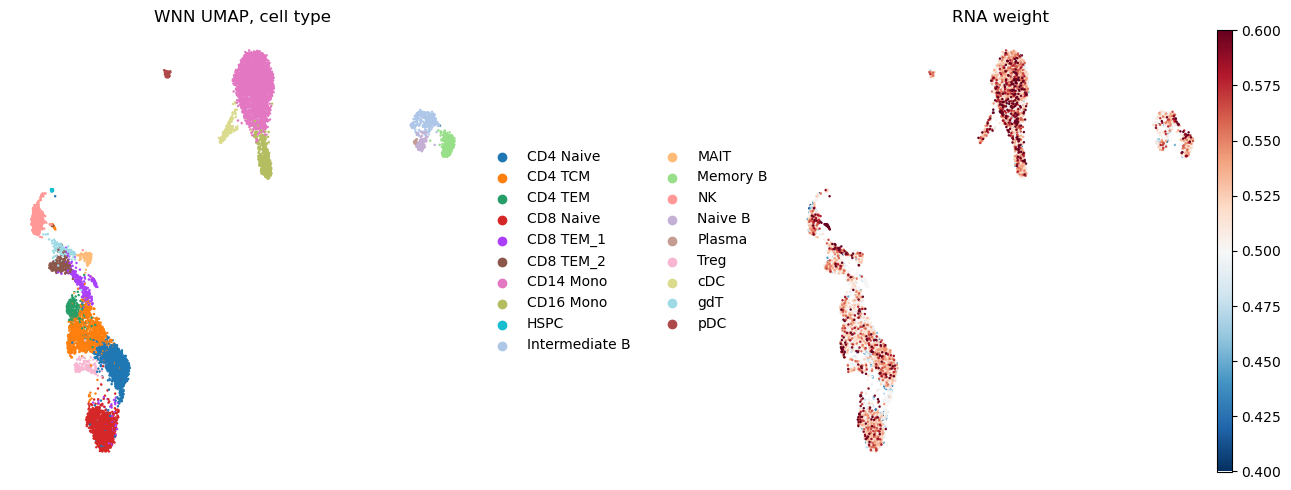

In [7]:
epi.tl.wnn(joint, reps=["X_pca", "X_lsi"], dims=[None, range(2, 51)], modality_names=["RNA", "ATAC"])
sc.tl.umap(joint, neighbors_key="wnn", random_state=0)
sc.tl.leiden(joint, neighbors_key="wnn", key_added="wnn_leiden", flavor="igraph", n_iterations=-1,
             directed=False, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sc.pl.umap(joint, color="cell_type", ax=axes[0], show=False, frameon=False, title="WNN UMAP, cell type")
sc.pl.umap(joint, color="wnn_weight_RNA", ax=axes[1], show=False, frameon=False, cmap="RdBu_r", vmin=0.4, vmax=0.6,
           title="RNA weight")
plt.tight_layout()

In this sample both modalities resolve the cell types about equally well,
so the weights stay close to 0.5 (roughly 0.42–0.60). Plasma cells lean
towards ATAC, and CD16 monocytes, HSPCs and γδ T cells slightly towards RNA.
The original Seurat analysis of this sample, stored in `obs["SCT.weight"]`,
shows the same compression around 0.5, with plasma cells lowest and
monocytes highest.

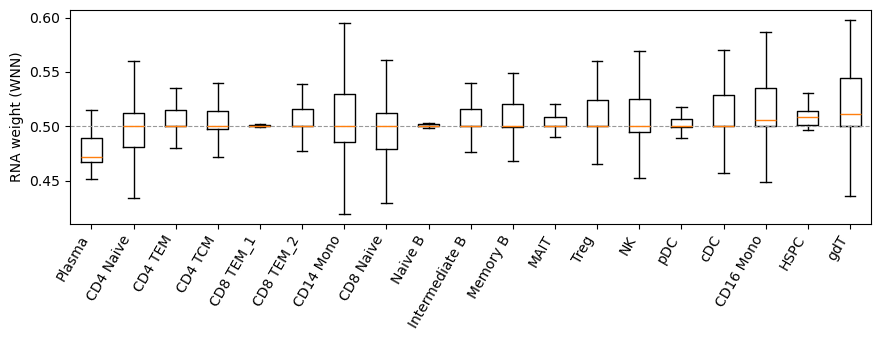

In [8]:
order = joint.obs.groupby("cell_type", observed=True)["wnn_weight_RNA"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.boxplot([joint.obs.loc[joint.obs.cell_type == c, "wnn_weight_RNA"] for c in order], showfliers=False)
ax.axhline(0.5, color="0.6", lw=0.8, ls="--")
ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order, rotation=60, ha="right")
ax.set_ylabel("RNA weight (WNN)")
plt.tight_layout()

## MultiVI

`epi.tl.multivi` wraps scvi-tools MultiVI and uses a GPU when one is
available. As in the scvi-tools tutorial, we keep features detected in at
least 1% of cells. Training runs until the validation loss stops improving
(up to 500 epochs); in our run that took about an hour on a shared H100, with
about 1 GB of GPU memory. Stopping much earlier gives a clearly worse latent
space (50 epochs: Leiden ARI 0.27).

In [9]:
import torch
keep_g = np.asarray((rna.X > 0).sum(axis=0)).ravel() >= 0.01 * rna.n_obs
keep_p = np.asarray((atac.X > 0).sum(axis=0)).ravel() >= 0.01 * atac.n_obs
rna_mv, atac_mv = rna[:, keep_g].copy(), atac[:, keep_p].copy()
print(f"{keep_g.sum():,} genes, {keep_p.sum():,} peaks; GPU: {torch.cuda.is_available()}")
model = epi.tl.multivi(rna_mv, atac_mv, seed=0)
joint.obsm["X_multivi"] = rna_mv.obsm["X_multivi"]
sc.pp.neighbors(joint, use_rep="X_multivi", n_neighbors=20, key_added="multivi", random_state=0)

13,315 genes, 79,386 peaks; GPU: True


Training:   0%|          | 0/500 [00:00<?, ?it/s]

Monitored metric reconstruction_loss_validation did not improve in the last 50 records. Best score: 22150.025. Signaling Trainer to stop.


## CCA between RNA and gene activity

`epi.tl.integrate` (CCA, as in ArchR / Seurat label transfer) is built for
*unpaired* data. For comparison we run it between RNA and an ATAC gene
activity (peak counts over gene body + 2 kb upstream) and average each cell's
two CCA vectors.

In [10]:
import scipy.sparse as sp
g, p = rna.var, atac.var
rows, cols = [], []
by_chrom = {c: (df["chromStart"].to_numpy(), df["chromEnd"].to_numpy(), np.where(p["chrom"] == c)[0])
            for c, df in p.groupby("chrom", observed=True)}
for gi, (c, s, e, strand) in enumerate(zip(g["chrom"], g["chromStart"], g["chromEnd"], g["strand"])):
    if c in by_chrom:
        s, e = (s - 2000, e) if strand == "+" else (s, e + 2000)
        ps, pe, pidx = by_chrom[c]
        hit = pidx[(ps < e) & (pe > s)]
        rows += [gi] * len(hit); cols += hit.tolist()
M = sp.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(rna.n_vars, atac.n_vars))
ga = sc.AnnData((sp.csr_matrix(atac.X) @ M.T).astype(np.float32), obs=rna.obs[[]].copy(), var=rna.var[[]].copy())
sc.pp.normalize_total(ga, target_sum=1e4); sc.pp.log1p(ga)
rl = rna.copy(); sc.pp.normalize_total(rl, target_sum=1e4); sc.pp.log1p(rl)
hvg = list(r.var_names)
ga_h, rl_h = ga[:, hvg].copy(), rl[:, hvg].copy()
epi.tl.integrate(ga_h, rl_h, method="cca", features=hvg, num_cc=30)
joint.obsm["X_cca"] = (ga_h.obsm["X_cca"].astype(float) + rl_h.obsm["X_cca"].astype(float)) / 2
sc.pp.neighbors(joint, use_rep="X_cca", n_neighbors=20, key_added="cca", random_state=0)

## Benchmark

Each representation gets a 20-NN graph; Leiden at resolution 1 (averaged
over three seeds) is compared with the cell-type labels (ARI, NMI). We also
report the fraction of each cell's 20 neighbours with the same label (kNN
purity) and the cell-type silhouette. WNN has no embedding, so its silhouette
is computed on its UMAP, which inflates it; read that one value with care.
Note that the labels themselves came from a Seurat WNN analysis, which
favours WNN-like graphs.

In [11]:
from sklearn import metrics as skm

ct = joint.obs["cell_type"].astype(str).to_numpy()
for key, rep in [("rna", "X_pca"), ("atac", "X_lsi_2_50")]:
    sc.pp.neighbors(joint, use_rep=rep, n_neighbors=20, key_added=key, random_state=0)

def scores(key, emb):
    aris, nmis = [], []
    for seed in range(3):
        sc.tl.leiden(joint, neighbors_key=key, key_added="_cl", resolution=1.0, flavor="igraph",
                     n_iterations=-1, directed=False, random_state=seed)
        aris.append(skm.adjusted_rand_score(ct, joint.obs["_cl"]))
        nmis.append(skm.normalized_mutual_info_score(ct, joint.obs["_cl"]))
    D = joint.obsp[joint.uns[key]["distances_key"]].tocsr()
    purity = np.mean([np.mean(ct[D.indices[D.indptr[i]:D.indptr[i + 1]]] == ct[i]) for i in range(D.shape[0])])
    sil = skm.silhouette_score(emb, ct, sample_size=5000, random_state=0)
    return {"ARI": np.mean(aris), "NMI": np.mean(nmis), "kNN_purity": purity, "silhouette": sil}

reps = {"RNA (PCA)": ("rna", joint.obsm["X_pca"]), "ATAC (LSI)": ("atac", joint.obsm["X_lsi_2_50"]),
        "CCA": ("cca", joint.obsm["X_cca"]), "combined_dims": ("combined", joint.obsm["X_combined"]),
        "WNN": ("wnn", joint.obsm["X_umap"]), "MultiVI": ("multivi", joint.obsm["X_multivi"])}
table = pd.DataFrame({m: scores(k, e) for m, (k, e) in reps.items()}).T
table.round(3)

,ARI,NMI,kNN_purity,silhouette
RNA (PCA),0.723,0.837,0.902,0.204
ATAC (LSI),0.728,0.832,0.890,0.057
CCA,0.650,0.787,0.841,0.080
combined_dims,0.741,0.848,0.920,0.131
WNN,0.807,0.868,0.932,0.441
MultiVI,0.515,0.746,0.899,0.194


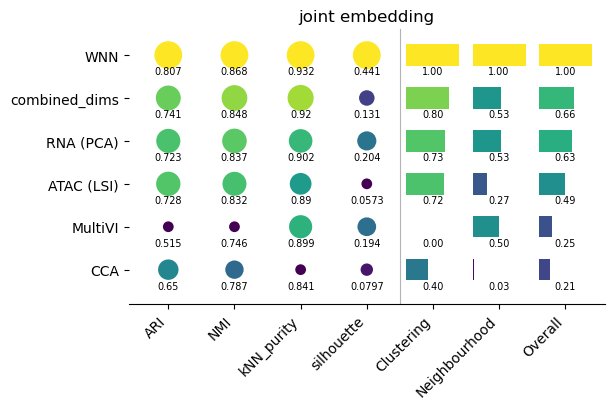

In [12]:
spec = {"ARI": ("clustering", True), "NMI": ("clustering", True),
        "kNN_purity": ("neighbourhood", True), "silhouette": ("neighbourhood", True)}
long = table.reset_index(names="method").melt(id_vars="method", var_name="metric", value_name="value")
long["task"] = "joint embedding"
long["category"] = long["metric"].map(lambda m: spec[m][0])
long["higher_is_better"] = True
fig = epi.translate.plot_benchmark(long, metrics=spec)

WNN gives the best clustering agreement (ARI 0.81) and neighbourhood purity
(0.93), with combined dims second (ARI 0.74), ahead of either modality alone.
MultiVI's latent space has neighbourhoods about as pure as RNA's (0.90), but
Leiden at resolution 1 splits it into clusters that match the labels less well
(ARI 0.52). CCA, built for unpaired data, is the weakest joint method. The
labels come from a Seurat WNN analysis, which may favour WNN-like graphs.

## Validation

| check | reference | result |
|---|---|---|
| `combined_dims` | ArchR 1.0.3 `addCombinedDims`, 4 configurations | identical to 1e-14 |
| `wnn` neighbour sets | Seurat 5.4.0 `FindMultiModalNeighbors`, same embeddings | median Jaccard 0.90 |
| `wnn` modality weights | same | Pearson r 0.94, median \|Δ\| 0.011 (gate r ≥ 0.95 not met) |
| `wnn` Leiden partitions | same, 10 seeds | ARI 0.84 ± 0.06 (Seurat vs re-seeded Seurat: 0.87 ± 0.06) |
| `read_10x_multiome` | independent `h5py` decode; scGLUE RNA counts | identical |

`epi.tl.wnn` was written from the paper's methods, without Seurat's code, so
small differences in the per-cell weights remain.